<a href="https://colab.research.google.com/github/VladyslavBiblyi/CSC-349-OL1/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## #1
####I loaded the Olivetti Faces dataset using Scikit-Learn. I separated the image features and target labels into X and y. Then I checked how many images, subjects, and features the dataset contains. Each image has 64 × 64 pixels, giving us 4,096 features. I plotted 20 sample faces in a 4 × 5 grid to see what the images look like and which subject each one belongs to.

{400}
{40}
{(400, 4096)}
{4096}
{(64, 64)}


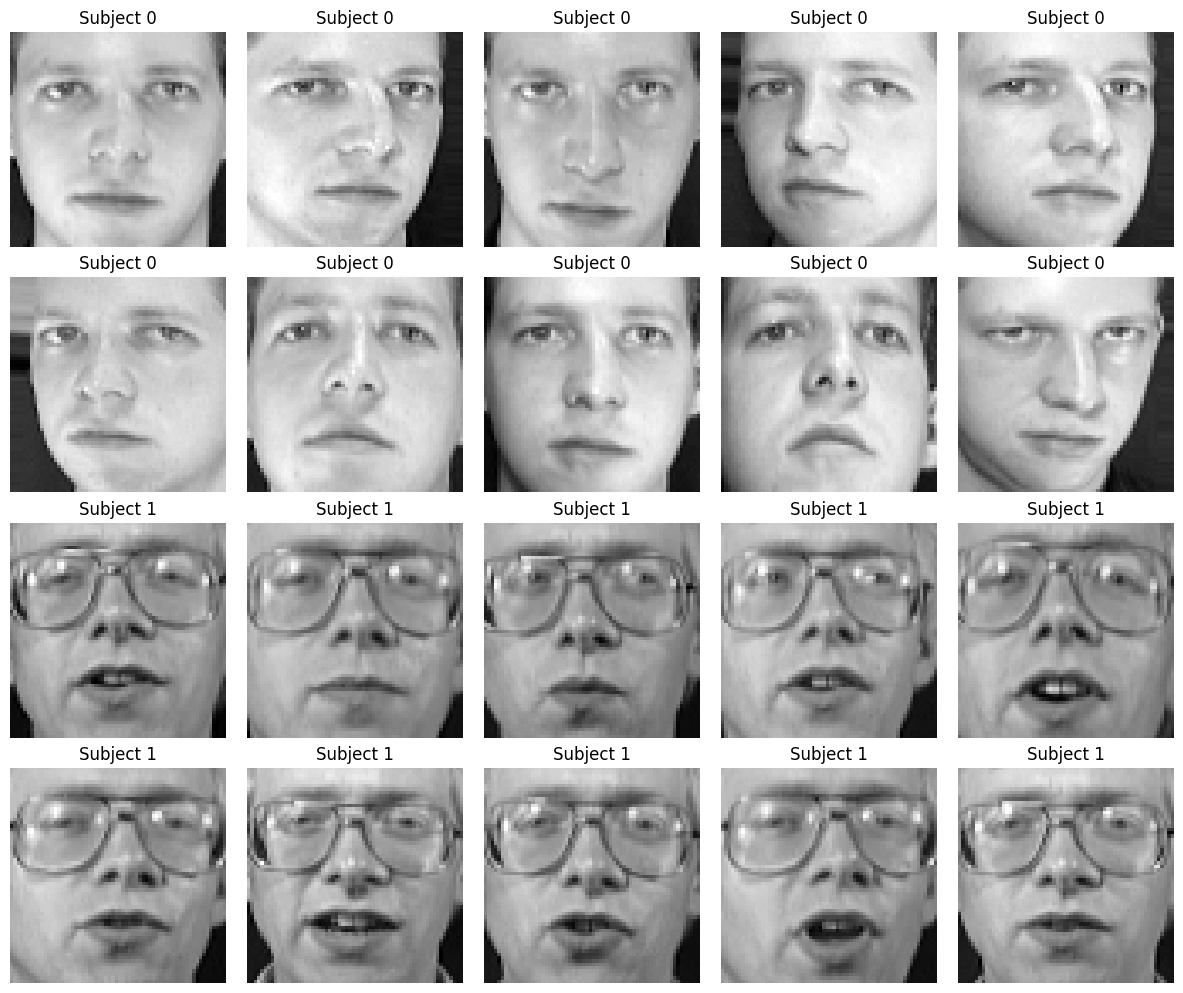

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, mean_squared_error, ConfusionMatrixDisplay

faces = fetch_olivetti_faces()
X = faces.data
y = faces.target

print({X.shape[0]})
print({len(np.unique(y))})
print({X.shape})
print({X.shape[1]})
print({faces.images[0].shape})

fig, axes = plt.subplots(4, 5, figsize=(12, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(faces.images[i], cmap='gray')
    ax.set_title(f'Subject {y[i]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

## #2
####I used PCA to see how much information each principal component keeps from the original dataset. I fitted a full PCA model and calculated the explained variance ratio for each component. I calculated the cumulative variance to find how many components are needed to preserve 90%, 95%, and 99%. I plotted both curves.

90% variance: 66
95% variance: 123
99% variance: 260


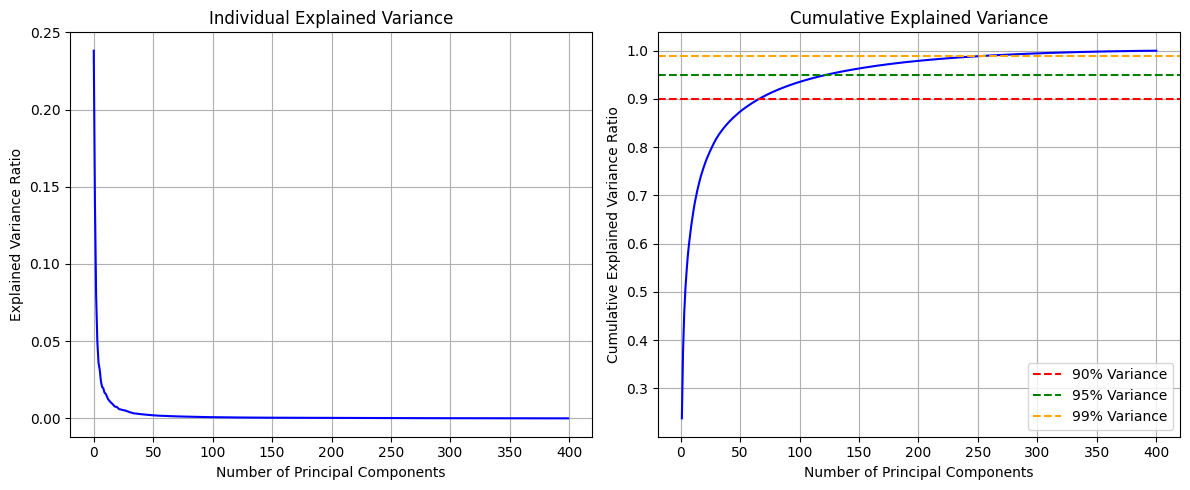

In [11]:
pca = PCA(n_components=None)
pca.fit(X)

explained_variance_ratio = pca.explained_variance_ratio_

cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

n_components_90 = np.argmax(cumulative_variance_ratio >= 0.90) + 1
n_components_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1
n_components_99 = np.argmax(cumulative_variance_ratio >= 0.99) + 1

print(f"90% variance: {n_components_90}")
print(f"95% variance: {n_components_95}")
print(f"99% variance: {n_components_99}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(explained_variance_ratio, color='b')
plt.title('Individual Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(np.arange(1, len(cumulative_variance_ratio) + 1),
         cumulative_variance_ratio, color='b')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Variance')
plt.axhline(y=0.95, color='g', linestyle='--', label='95% Variance')
plt.axhline(y=0.99, color='orange', linestyle='--', label='99% Variance')
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## #3
####I selected 5 faces from different subjects and reconstructed them using 10, 50, 100, 200, and 300 components. I compared each image with the original to see how much detail was lost. I calculated MSE for each number of components to measure the error.

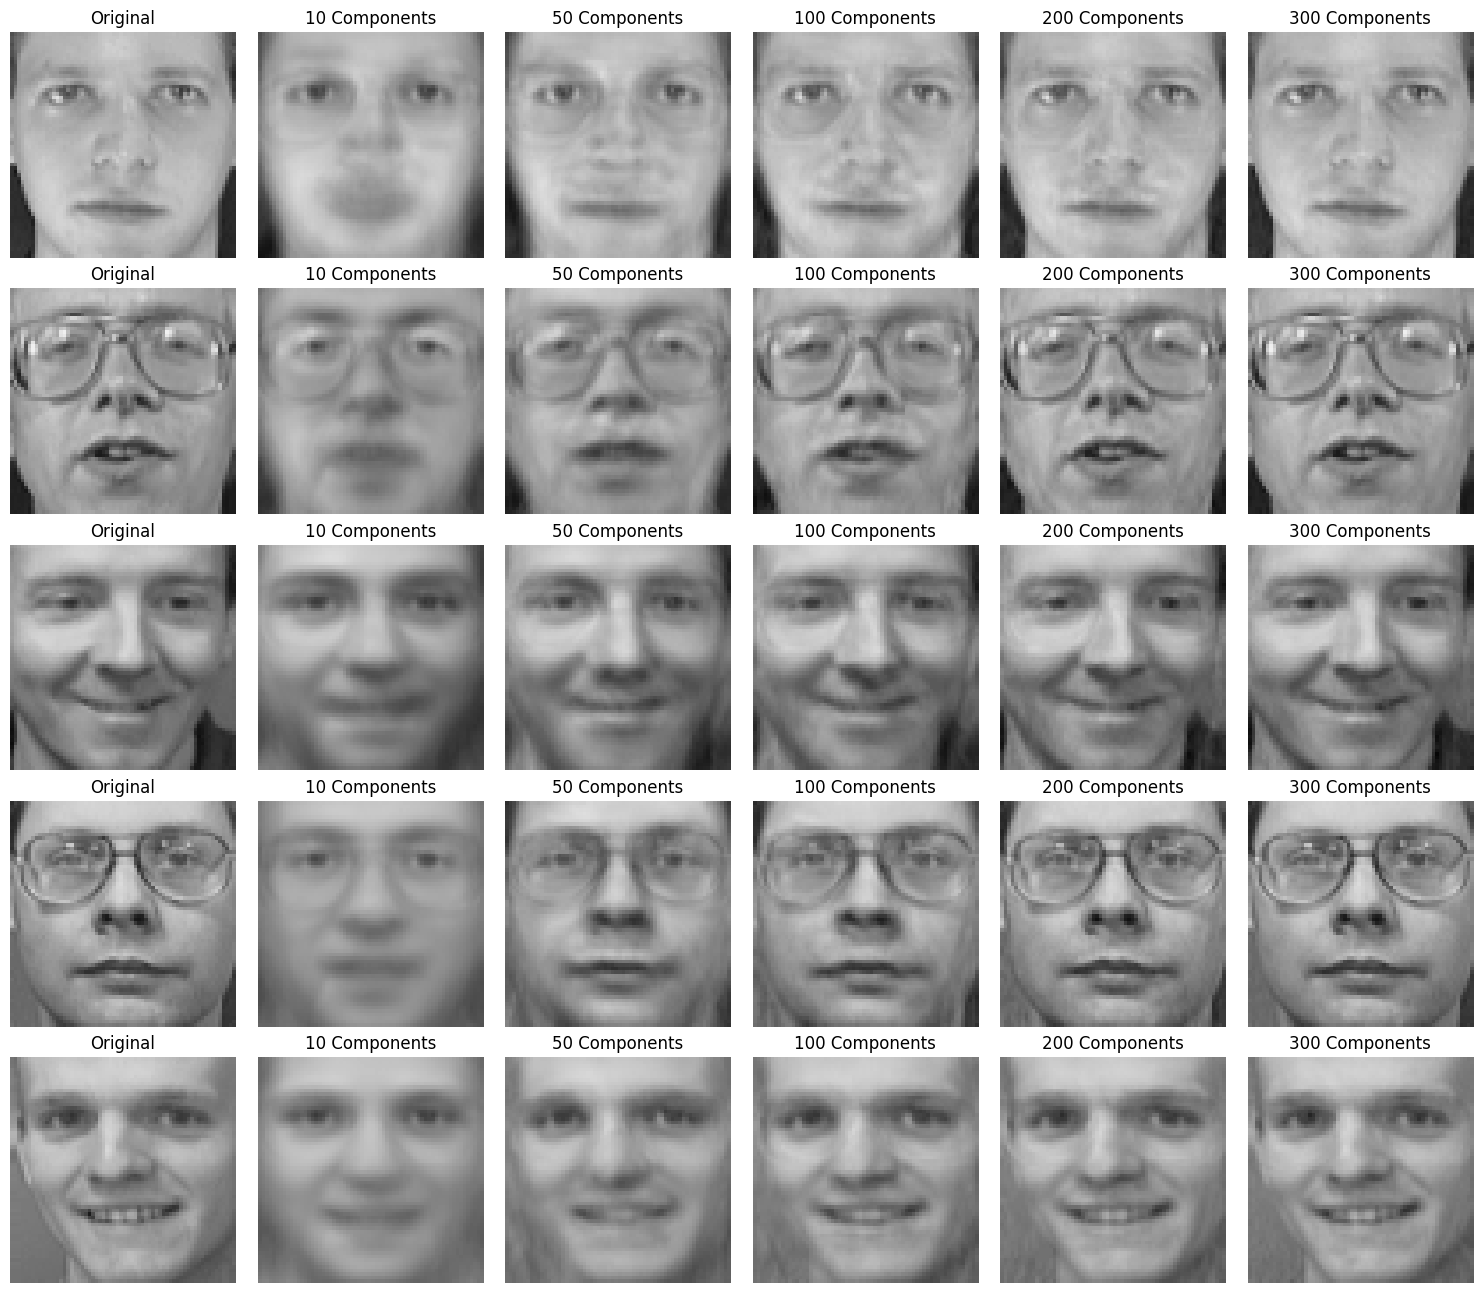

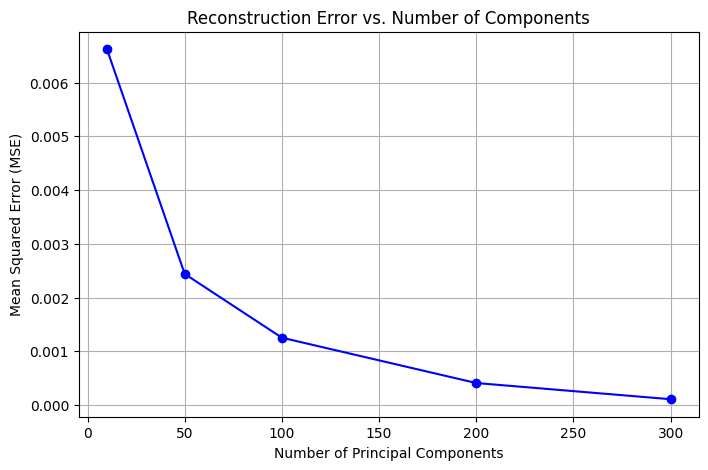

10 Components - MSE: 0.006622
50 Components - MSE: 0.002439
100 Components - MSE: 0.001252
200 Components - MSE: 0.000409
300 Components - MSE: 0.000107


In [12]:
component_levels = [10, 50, 100, 200, 300]

sample_indices = [0, 10, 20, 30, 40]

fig, axes = plt.subplots(5, 6, figsize=(15, 13))

for i, idx in enumerate(sample_indices):
    original_img = X[idx].reshape(64, 64)

    axes[i, 0].imshow(original_img, cmap='gray', vmin=0, vmax=1)
    axes[i, 0].set_title('Original')
    axes[i, 0].axis('off')

mse_values = []

for j, n_comp in enumerate(component_levels):
    pca_temp = PCA(n_components=n_comp, random_state=42)
    X_red_temp = pca_temp.fit_transform(X)
    X_rec_temp = pca_temp.inverse_transform(X_red_temp)

    mse = mean_squared_error(X, X_rec_temp)
    mse_values.append(mse)

    for i, idx in enumerate(sample_indices):
        rec_img = X_rec_temp[idx].reshape(64, 64)

        axes[i, j + 1].imshow(rec_img, cmap='gray', vmin=0, vmax=1)
        axes[i, j + 1].set_title(f'{n_comp} Components')
        axes[i, j + 1].axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(component_levels, mse_values, marker='o', color='b')

plt.title('Reconstruction Error vs. Number of Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Mean Squared Error (MSE)')
plt.grid(True)
plt.show()

for k, mse in zip(component_levels, mse_values):
    print(f"{k} Components - MSE: {mse:.6f}")

## #4
####I used the PCA model from Task 2 to visualize the first 15 Eigenfaces. I reshaped them back into 64 × 64 images and displayed them in a 3 × 5 grid. I added the percentage of variance explained by each component.

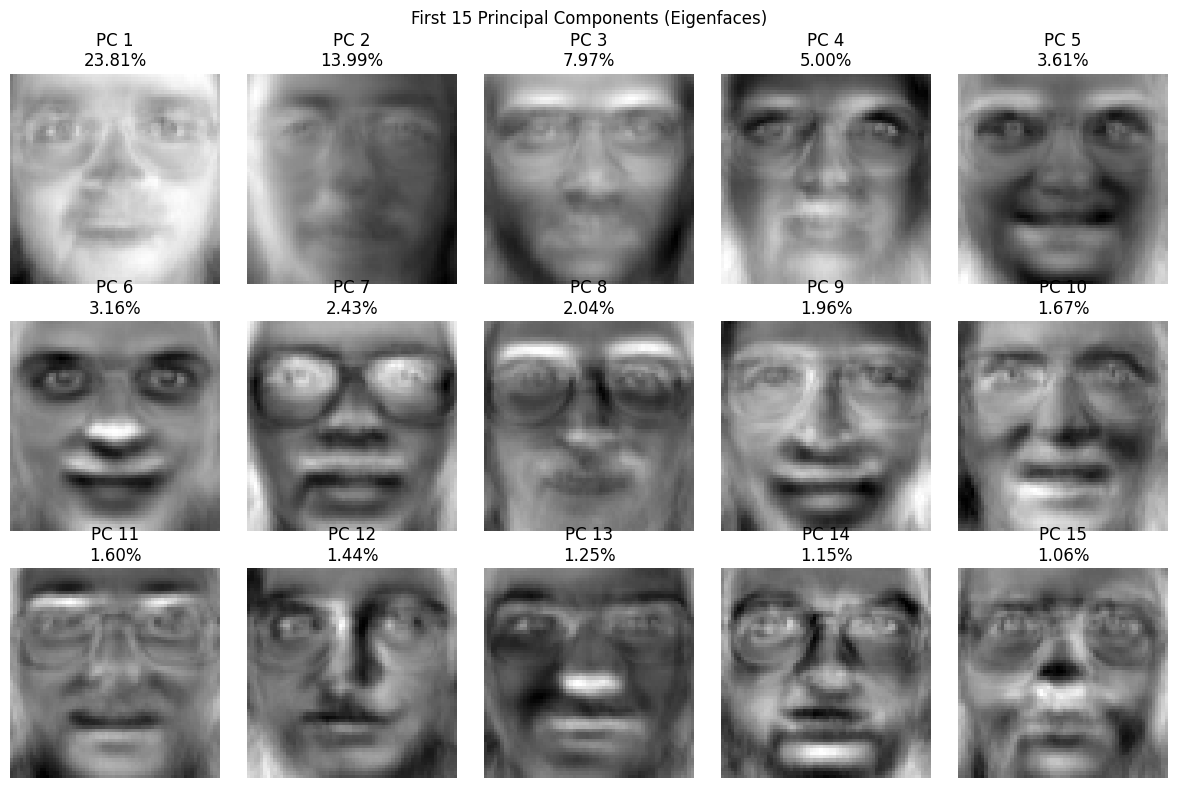

In [13]:
num_components_to_plot = 15

fig, axes = plt.subplots(3, 5, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    comp_img = pca.components_[i].reshape(64, 64)

    comp_img_normalized = (comp_img - comp_img.min()) / (comp_img.max() - comp_img.min())

    ax.imshow(comp_img_normalized, cmap='gray')
    ax.set_title(f'PC {i + 1}\n{explained_variance_ratio[i] * 100:.2f}%')
    ax.axis('off')

plt.suptitle('First 15 Principal Components (Eigenfaces)')
plt.tight_layout()
plt.show()

## 5
####I split the dataset into 80 training and 20 testing. I trained the first model using all 4,096 features. For the second model, I used a pipeline with PCA to keep 95% of the variance before training LR. I measured the test accuracy and training time of both models and plotted them to compare their performance.

Training Logistic Regression on raw features...
Raw Features Accuracy: 0.9625
Training Time: 32.31 seconds

Training Logistic Regression on PCA-reduced features...
PCA-Reduced Features: 111 components
PCA-Reduced Accuracy: 0.9625
Training Time: 0.59 seconds


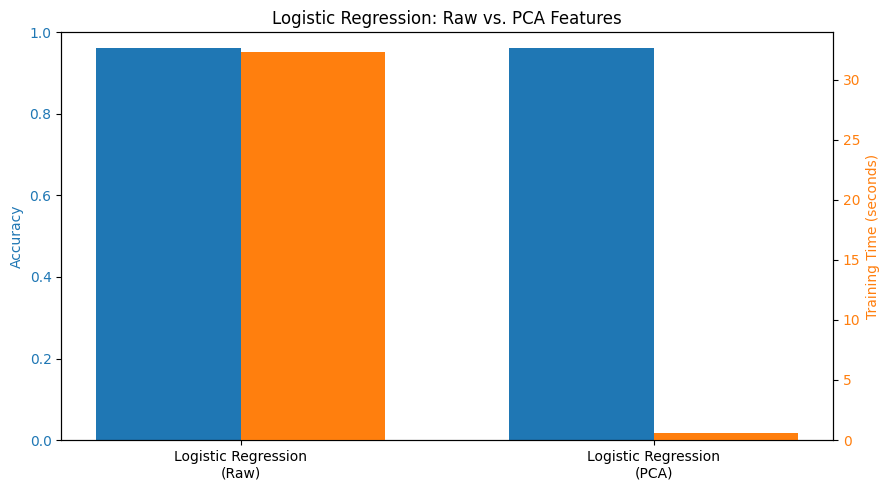

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training Logistic Regression on raw features...")

start_time = time.time()

clf_raw = LogisticRegression(max_iter=1000, random_state=42)
clf_raw.fit(X_train, y_train)

raw_time = time.time() - start_time

y_pred_raw = clf_raw.predict(X_test)
raw_accuracy = accuracy_score(y_test, y_pred_raw)

print(f"Raw Features Accuracy: {raw_accuracy:.4f}")
print(f"Training Time: {raw_time:.2f} seconds")

print("\nTraining Logistic Regression on PCA-reduced features...")

start_time = time.time()

clf_pca = make_pipeline(
    PCA(n_components=0.95),
    LogisticRegression(max_iter=1000, random_state=42)
)

clf_pca.fit(X_train, y_train)

pca_time = time.time() - start_time

y_pred_pca = clf_pca.predict(X_test)
pca_accuracy = accuracy_score(y_test, y_pred_pca)

pca_clf = clf_pca.named_steps['pca']
X_train_reduced = pca_clf.transform(X_train)
X_test_reduced = pca_clf.transform(X_test)

print(f"PCA-Reduced Features: {pca_clf.n_components_} components")
print(f"PCA-Reduced Accuracy: {pca_accuracy:.4f}")
print(f"Training Time: {pca_time:.2f} seconds")

models = ['Logistic Regression\n(Raw)', 'Logistic Regression\n(PCA)']
accuracies = [raw_accuracy, pca_accuracy]
train_times = [raw_time, pca_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.bar(x - width/2, accuracies, width, color='tab:blue')
ax1.set_ylabel('Accuracy', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()
ax2.bar(x + width/2, train_times, width, color='tab:orange')
ax2.set_ylabel('Training Time (seconds)', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

ax1.set_xticks(x)
ax1.set_xticklabels(models)
plt.title('Logistic Regression: Raw vs. PCA Features')
fig.tight_layout()
plt.show()

## #6
####I trained a Support Vector Classifier with an RBF kernel using the PCA-reduced features from Task 5. Unlike LR, the RBF kernel can find non-linear relationships between features. I measured the training time and test accuracy to compare it with the linear model. I also plotted confusion matrices for both models to see how well they predicted the different subjects.

Training SVC with RBF kernel...
SVC (RBF) Accuracy: 0.9375
Training Time: 0.03 seconds
Logistic Regression (PCA) Accuracy: 0.9625


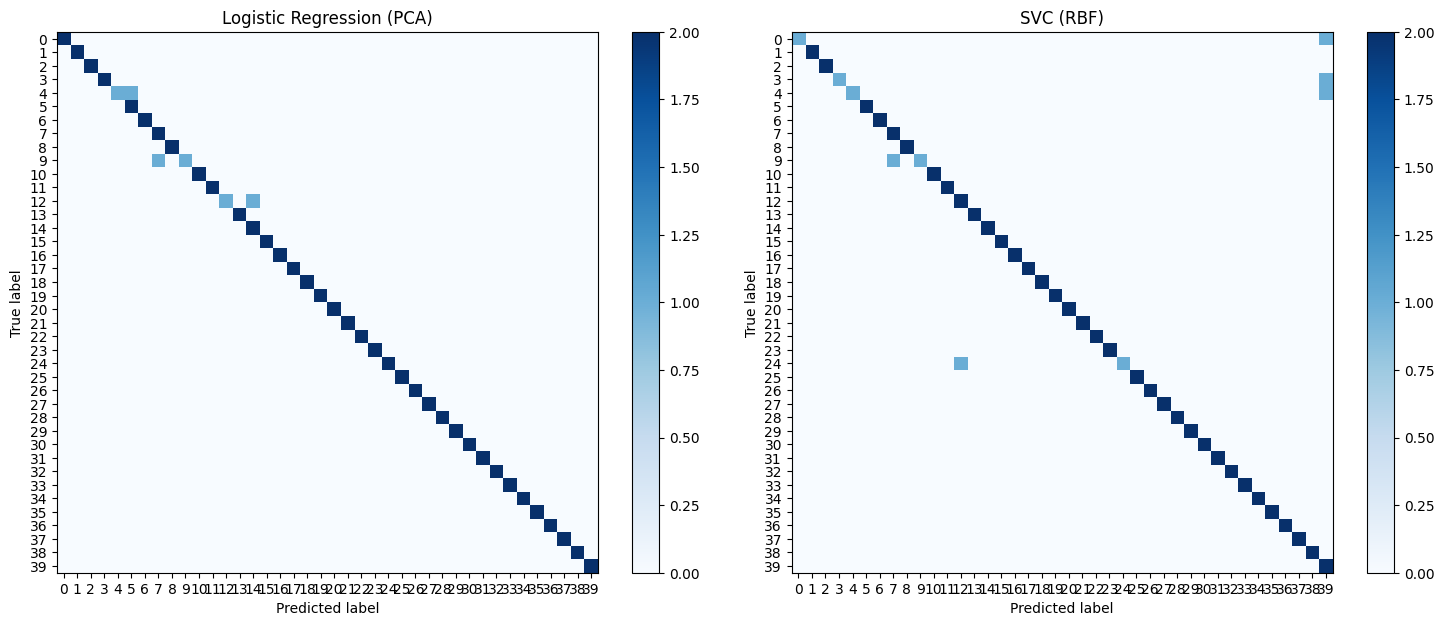

In [15]:
print("Training SVC with RBF kernel...")

start_time = time.time()

rbf_svm = SVC(kernel='rbf', random_state=42)
rbf_svm.fit(X_train_reduced, y_train)

svm_time = time.time() - start_time

y_pred_svm = rbf_svm.predict(X_test_reduced)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(f"SVC (RBF) Accuracy: {svm_accuracy:.4f}")
print(f"Training Time: {svm_time:.2f} seconds")
print(f"Logistic Regression (PCA) Accuracy: {pca_accuracy:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_pca, ax=axes[0], cmap='Blues',
    include_values=False
)
axes[0].set_title('Logistic Regression (PCA)')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm, ax=axes[1], cmap='Blues',
    include_values=False
)
axes[1].set_title('SVC (RBF)')

plt.tight_layout()
plt.show()

## #7
####Here I created an ensemble classifier that combines three different models: a Polynomial Kernel SVM with degree 2, an RBF Kernel SVM, and a RF with 100 trees. I used soft voting. I trained the ensemble using the same PCA-reduced features and measured its accuracy and training time. Finally, I compared the results with Logistic Regression and the RBF SVM from the previous tasks.

In [16]:
print("Training Ensemble Classifier on PCA-reduced features...")

start_time = time.time()

poly_svm = SVC(kernel='poly', degree=2, probability=True, random_state=42)
rbf_svm_ensemble = SVC(kernel='rbf', probability=True, random_state=42)
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)

ensemble_clf = VotingClassifier(
    estimators=[
        ('poly_svm', poly_svm),
        ('rbf_svm', rbf_svm_ensemble),
        ('random_forest', random_forest)
    ],
    voting='soft'
)

ensemble_clf.fit(X_train_reduced, y_train)
ensemble_time = time.time() - start_time

y_pred_ensemble = ensemble_clf.predict(X_test_reduced)
ensemble_accuracy = accuracy_score(y_test, y_pred_ensemble)

print(f"Ensemble Classifier Accuracy: {ensemble_accuracy:.4f}")
print(f"Training Time: {ensemble_time:.2f} seconds")

print(f"\nLogistic Regression (PCA): {pca_accuracy:.4f}")
print(f"SVC (RBF): {svm_accuracy:.4f}")
print(f"Ensemble Classifier: {ensemble_accuracy:.4f}")

Training Ensemble Classifier on PCA-reduced features...
Ensemble Classifier Accuracy: 0.9500
Training Time: 0.99 seconds

Logistic Regression (PCA): 0.9625
SVC (RBF): 0.9375
Ensemble Classifier: 0.9500


## #8
####I compared all four models that I trained in the previous tasks: LR with raw features, LR with PCA, RBF SVM with PCA, and the Voting Ensemble with PCA. I used the accuracy and training time values collected earlier instead of training the models again. I plotted both measurements on the same graph using two y-axes.

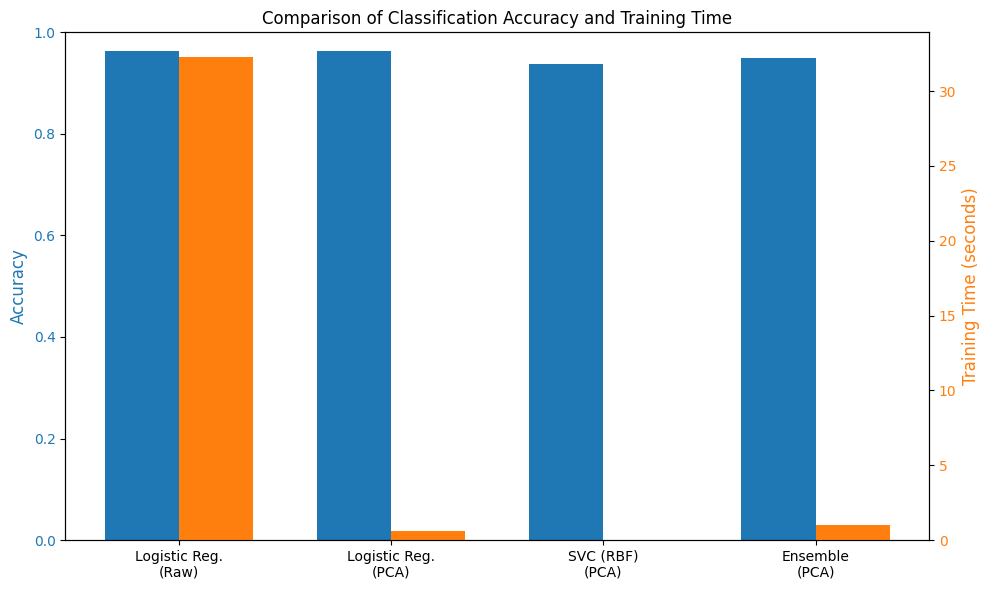

In [17]:
models = [
    'Logistic Reg.\n(Raw)',
    'Logistic Reg.\n(PCA)',
    'SVC (RBF)\n(PCA)',
    'Ensemble\n(PCA)'
]

accuracies = [raw_accuracy, pca_accuracy, svm_accuracy, ensemble_accuracy]
train_times = [raw_time, pca_time, svm_time, ensemble_time]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:blue'
ax1.set_ylabel('Accuracy', color=color, fontsize=12)
ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Training Time (seconds)', color=color, fontsize=12)
ax2.bar(x + width/2, train_times, width, label='Training Time (s)', color=color)
ax2.tick_params(axis='y', labelcolor=color)

ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Comparison of Classification Accuracy and Training Time')
fig.tight_layout()
plt.show()